# QumPy: a simple example

We build a Bell circuit, draw it, measure it 1000 times and plot a histogram of
the results.

**Installation** (only needed once). If QumPy is not installed yet, remove the
`#` at the start of the line below, run the cell, then restart the kernel.

In [1]:
# %pip install "qumpy[noisy] @ https://github.com/yigitcaneym/QumPy/archive/refs/heads/main.zip"

## 1. Import and set up

In [2]:
import qumpy as qp
from qumpy import Qum

Qum.shots = 1000   # every .run() measures 1000 times

## 2. Build and draw the circuit

A Hadamard on qubit 0, then a CNOT: the result is the Bell state (|00⟩ + |11⟩)/√2.

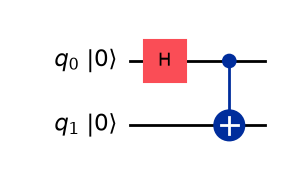

In [3]:
c = qp.Circuit(2).h(0).cx(0, 1)
c.draw()

Before measuring, we can look at the state itself:

In [4]:
qp.dirac(c.state())

'0.7071|00⟩ + 0.7071|11⟩'

## 3. Measure and plot a histogram

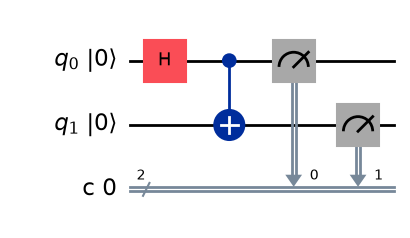

In [5]:
c.measure()
c.draw()

Counts({'00': 498, '11': 502}, shots=1000)


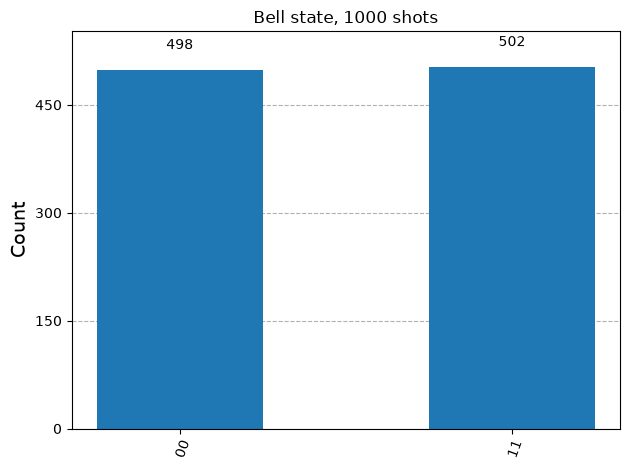

In [6]:
counts = c.run()
print(counts)
counts.plot(title="Bell state, 1000 shots")

Only `00` and `11` appear, each about half of the time: the two qubits are
entangled.

## 4. Bonus: a noisy simulation that imitates a real device

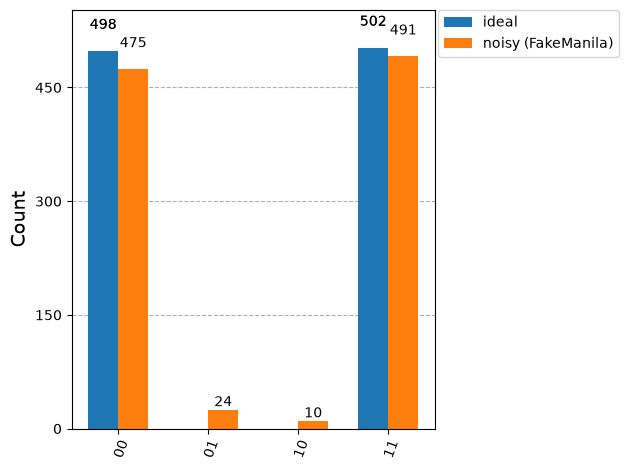

In [7]:
noisy = c.run(backend="noisy")
qp.histogram(counts, noisy, legend=["ideal", "noisy (FakeManila)"])

On the noisy device a few `01` and `10` results show up too: these are hardware errors.